# Week 10A: Working with web APIs and text data

Learn to request web data, build GeoDataFrames, and explore text from Philadelphia 311 requests.

**Lecture guide:** API fundamentals → Geospatial API examples → Philadelphia 311 → Text mining

## Today’s agenda

- Understand API endpoints and query parameters.
- Request geospatial data from USGS, CARTO, and GeoServices.
- Collect Philadelphia 311 records and summarize their descriptions.

### Before you start

> **Important:**
>
> Update your local environment!
>
> - Small update to the course's Python environment
> - Update the environment on your laptop using [these instructions](https://musa-550-fall-2023.github.io/resource/mamba.html#updating-an-existing-environment) on course website

In [54]:
# !pip install holoviews
# !pip install hvplot
# !pip install seaborn

In [55]:
import geopandas as gpd
import holoviews as hv
import hvplot.pandas
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

In [56]:
# Show all columns
pd.options.display.max_columns = 999

## Part 1: API fundamentals and geospatial data

Or, how to pull data from the web using Python

### What is an API?

> (noun): A particular set of rules and specifications that software programs can follow to communicate with each other and exchange data.

#### Examples of public APIs

- Socrata Open Data: [https://dev.socrata.com/](https://dev.socrata.com/)
- Open Data Philly: [https://opendataphilly.org](https://opendataphilly.org)
- US Census Bureau: [https://www.census.gov/data/developers/data-sets.html](https://www.census.gov/data/developers/data-sets.html)
- Bureau of Labor Statistics: [https://www.bls.gov/developers/](https://www.bls.gov/developers/)
- US Geological Survey: [https://www.usgs.gov/products/data-and-tools/apis](https://www.usgs.gov/products/data-and-tools/apis)
- US Environmental Protection Agency: [https://www.epa.gov/enviro/web-services](https://www.epa.gov/enviro/web-services)
- Google APIs: [https://console.cloud.google.com/apis/library](https://console.cloud.google.com/apis/library)
- Facebook: [https://developers.facebook.com/docs/apis-and-sdks/](https://developers.facebook.com/docs/apis-and-sdks/)
- Twitter: [https://developer.twitter.com/en/docs/api-reference-index.html](https://developer.twitter.com/en/docs/api-reference-index) (RIP 💀)
- Foursquare: [https://developer.foursquare.com/](https://developer.foursquare.com/)
- Instagram: [https://www.instagram.com/developer/](https://www.instagram.com/developer/)
- Yelp: [https://www.yelp.com/developers](https://www.instagram.com/developer/)

> **Note:**
>
> When accessing data via API, many services will require you to register an API key to prevent you from overloading the service with requests.

### Example 1: Automated data feeds

The simplest form of API is when data providers maintain data files via a URL that are automatically updated with new data over time.

#### USGS earthquake feeds

This is an API for near-real-time data about earthquakes, and data is provided in GeoJSON format over the web. 

The API has a separate endpoint for each version of the data that users might want. No authentication is required.

API documentation:

[http://earthquake.usgs.gov/earthquakes/feed/v1.0/geojson.php](http://earthquake.usgs.gov/earthquakes/feed/v1.0/geojson.php)

Sample API endpoint, for magnitude 4.5+ earthquakes in past day:

[http://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_day.geojson](http://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_day.geojson)

GeoPandas can read GeoJSON files from the web directly. Simply pass the URL to the `gpd.read_file()` function:

In [57]:
# Download data on magnitude 2.5+ quakes from the past week
endpoint_url = (
    "http://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/2.5_week.geojson"
)
earthquakes = gpd.read_file(endpoint_url)

In [58]:
earthquakes.head()

,id,mag,place,time,updated,tz,url,detail,felt,cdi,mmi,alert,status,tsunami,sig,net,code,ids,sources,types,nst,dmin,rms,gap,magType,type,title,geometry
0,us6000u40h,2.50,"13 km SSW of Bigfoot, Texas",1792637054522,1792637802040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,NaN,None,reviewed,0,96,us,6000u40h,",us6000u40h,",",us,",",origin,phase-data,",9,0.17800,0.34,99,mb_lg,earthquake,"M 2.5 - 13 km SSW of Bigfoot, Texas",POINT Z (-98.9157 28.9365 8.43)
1,nc75453186,3.25,"14 km SE of Petrolia, CA",1792633390400,1792639564766,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,7.0,3.1,NaN,None,automatic,0,165,nc,75453186,",nc75453186,us6000u405,",",nc,us,",",dyfi,focal-mechanism,nearby-cities,origin,pha...",41,0.01543,0.17,108,ml,earthquake,"M 3.3 - 14 km SE of Petrolia, CA",POINT Z (-124.17083 40.2345 10.99)
2,us6000u3zu,4.40,"30 km NW of Albardón, Argentina",1792631283006,1792635892040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,NaN,None,reviewed,0,298,us,6000u3zu,",us6000u3zu,",",us,",",origin,phase-data,",26,0.33100,0.53,74,mb,earthquake,"M 4.4 - 30 km NW of Albardón, Argentina",POINT Z (-68.7255 -31.2167 103.228)
3,us6000u3yp,5.00,Reykjanes Ridge,1792619928618,1792620741040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,NaN,None,reviewed,0,385,us,6000u3yp,",us6000u3yp,",",us,",",origin,phase-data,",88,7.24300,0.66,50,mb,earthquake,M 5.0 - Reykjanes Ridge,POINT Z (-34.1306 56.863 10)
4,us6000u3yj,5.30,Reykjanes Ridge,1792618735441,1792619509040,None,https://earthquake.usgs.gov/earthquakes/eventp...,https://earthquake.usgs.gov/earthquakes/feed/v...,NaN,NaN,NaN,None,reviewed,0,432,us,6000u3yj,",us6000u3yj,",",us,",",origin,phase-data,",85,7.25900,0.93,50,mww,earthquake,M 5.3 - Reykjanes Ridge,POINT Z (-34.1689 56.8137 10)


Let's explore the data interactively with Folium:

In [59]:
# !pip install folium matplotlib mapclassify
# !pip install folium

In [60]:
from mapclassify import classify

In [61]:
earthquakes.explore()

# earthquakes.plot()

Lots of other automated feeds available, updated every minute:

![](imgs/usgs-1.png){width=312}
![](imgs/usgs-2.png){width=300}

### Example 2: The CARTO API

- Philadelphia hosts the majority of its open data on OpenDataPhilly in the cloud using CARTO
- They provide an API to download the data
- You can access the API documentation on the dataset page on OpenDataPhilly

For example: shooting victims in Philadelphia

[https://www.opendataphilly.org/dataset/shooting-victims](https://www.opendataphilly.org/dataset/shooting-victims)

and the API documentation:

[https://cityofphiladelphia.github.io/carto-api-explorer/#shootings](https://cityofphiladelphia.github.io/carto-api-explorer/#shootings)

Let's take a look at the download URL for the data in the GeoJSON format:

![](imgs/shooting-victims-api.png){width=500}

#### The anatomy of an API request

![](imgs/carto-api.png){width="900"}

- **Base URL**: shown in blue
- **?**: shown in purple; it separates the base URL from the query parameters
- **Query parameters**: underlined in red; these parameters allow the user to customize the data response
- **&**: underlined in green; the separator between the query parameters

So, let's break down the URL into its component parts:

In [62]:
# The API endpoint
carto_api_endpoint = "https://phl.carto.com/api/v2/sql"

# The query parameters
params = {
    "q": "SELECT * FROM shootings",
    "format": "geojson",
    "skipfields": "cartodb_id",
    # Note: we won't need the filename parameter, since we're not saving the data to a file
    # "filename": "shootings"
}


> **Note:**
>
> **Note: SQL Queries**
> The `q` parameter is a *SQL query*. It allows you to select a specific subset of data from the larger database.
>
> CARTO API documentation: [https://carto.com/developers/sql-api/](https://carto.com/developers/sql-api/)
>
> SQL documentation: [https://www.postgresql.org/docs/9.1/sql.html](https://www.postgresql.org/docs/9.1/sql.html)
>
> **General Query Syntax**
>
> `SELECT [field names] FROM [table name] WHERE [query]`

#### Request data with Python

We'll use Python's `requests` library to use a "get" request to query the API endpoint with our desired query. Similar to our web scraping requests!

In [63]:
import requests

Let's make the get request and pass the query parameters via the `params` keyword:

In [64]:
response = requests.get(carto_api_endpoint, params=params)

response

<Response [200]>

In [65]:
# Get the returned data in JSON format
# This is a dictionary
features = response.json()
# features

In [66]:
type(features)

dict

In [67]:
# What are the keys?
list(features.keys())

['type', 'features']

In [68]:
features["type"]

'FeatureCollection'

In [69]:
# Let's look at the first feature
features["features"][0]

{'type': 'Feature',
 'geometry': {'type': 'Point', 'coordinates': [-75.070974, 40.045313]},
 'properties': {'year': '2015',
  'dist': '2',
  'dc_key': 201502033124,
  'code': '400',
  'date_': '2015-05-25',
  'time': '03:30:00',
  'race': 'W',
  'sex': 'M',
  'latino': '1',
  'age': 20,
  'wound': 'Leg',
  'inside': '0',
  'outside': '1',
  'fatal': '0',
  'officer_involved': 'N',
  'offender_injured': 'N',
  'offender_deceased': 'N',
  'location': '1500 BLOCK Longshore Ave',
  'point_x': -75.07097363,
  'point_y': 40.04531338,
  'gdb_geomattr_data': None,
  'objectid': 1}}

Use the `GeoDataFrame.from_features()` function to create a GeoDataFrame.

In [70]:
shootings = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")

> **Important:**
>
> Don't forget to specify the CRS of the input data when using `GeoDataFrame.from_features()`.

In [71]:
shootings.head()

,geometry,year,dist,dc_key,code,date_,time,race,sex,latino,age,wound,inside,outside,fatal,officer_involved,offender_injured,offender_deceased,location,point_x,point_y,gdb_geomattr_data,objectid
0,POINT (-75.07097 40.04531),2015,2,201502033124,400,2015-05-25,03:30:00,W,M,1,20.0,Leg,0,1,0,N,N,N,1500 BLOCK Longshore Ave,-75.070974,40.045313,None,1
1,POINT (-75.09035 40.04016),2015,2,201502034321,400,2015-05-29,17:30:00,B,M,0,20.0,Hand,0,1,0,N,N,N,6100 BLOCK Algon Ave,-75.090348,40.040162,None,2
2,POINT (-75.093 40.0307),2015,2,201502061273,3400,2015-09-20,06:16:00,B,M,0,34.0,Leg,1,0,0,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,None,3
3,POINT (-75.093 40.0307),2015,2,201502061273,3400,2015-09-20,06:16:00,B,M,0,23.0,Multiple,1,0,0,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,None,4
4,POINT (-75.093 40.0307),2015,2,201502061273,3400,2015-09-20,06:16:00,B,M,0,42.0,Multiple,1,0,0,N,N,N,900 BLOCK Pratt St,-75.092997,40.030702,None,5


#### At-home exercise: Map shooting incidents

##### Step 1: Prepare the data

- Drop rows where the geometry is NaN
- Convert to a better CRS (e.g., 3857)
- Load city limits from Open Data Philly and trim to those only within city limits (some shootings have wrong coordinates, outside Philadelphia!)

In [72]:
# make sure we remove missing geometries
shootings = shootings.dropna(subset=["geometry"])

# convert to a better CRS
shootings = shootings.to_crs(epsg=3857)

In [73]:
city_limits = gpd.read_file(
    "https://opendata.arcgis.com/datasets/405ec3da942d4e20869d4e1449a2be48_0.geojson"
).to_crs(epsg=3857)

HTTPError: HTTP Error 500: Internal Server Error

In [ ]:
# Remove any shootings that are outside the city limits
shootings = gpd.sjoin(shootings, city_limits, predicate="within", how="inner").drop(
    columns=["index_right"]
)

##### Step 2: Plot the points

A quick plot with geopandas to show the shootings as points, and overlay Philadelphia ZIP codes.

In [ ]:
# From Open Data Philly
zip_codes = gpd.read_file(
    "https://opendata.arcgis.com/datasets/b54ec5210cee41c3a884c9086f7af1be_0.geojson"
).to_crs(epsg=3857)

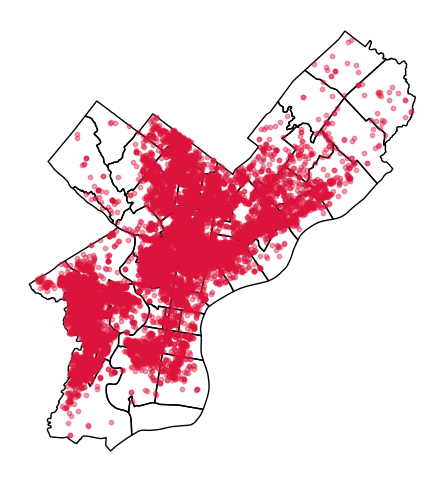

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

# ZIP Codes
zip_codes.to_crs(epsg=3857).plot(ax=ax, facecolor="none", edgecolor="black")

# Shootings
shootings.plot(ax=ax, color="crimson", markersize=10, alpha=0.4)
ax.set_axis_off()

##### Step 3: Create a hexbin map

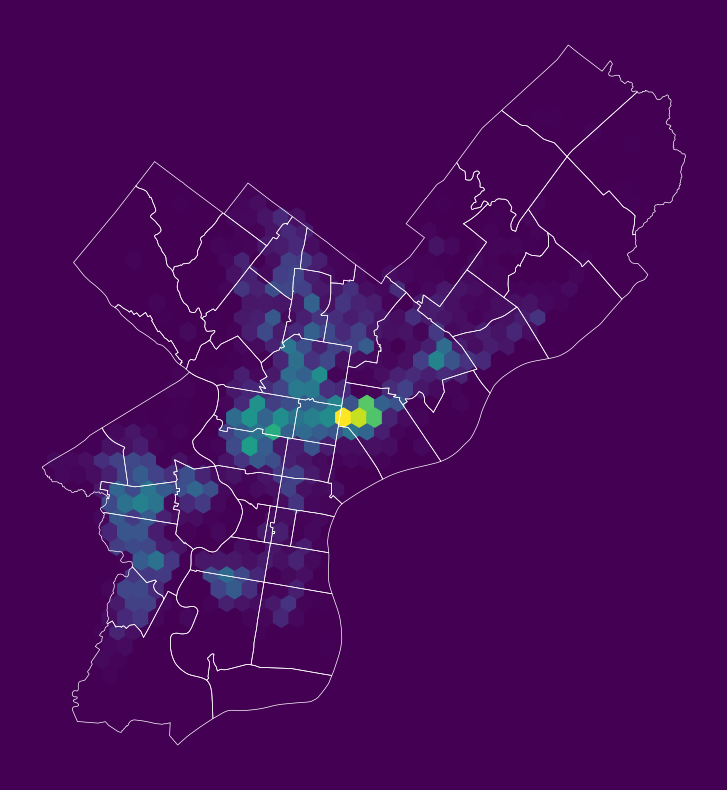

In [74]:
# Initialize the axes
fig, ax = plt.subplots(figsize=(10, 10), facecolor=plt.get_cmap("viridis")(0))

# Convert to Web Mercator and plot the hexbins
x = shootings.geometry.x
y = shootings.geometry.y
ax.hexbin(x, y, gridsize=40, mincnt=1, cmap="viridis")

# overlay the city limits
zip_codes.to_crs(epsg=3857).plot(
    ax=ax, facecolor="none", linewidth=0.5, edgecolor="white"
)

ax.set_axis_off()

#### Query pattern 1: Count rows

The SQL `COUNT` function can be applied to count all rows.

In [75]:
response = requests.get(
    carto_api_endpoint, params={"q": "SELECT COUNT(*) FROM shootings"}
)

In [76]:
response.json()

{'rows': [{'count': 18012}],
 'time': 0.003,
 'fields': {'count': {'type': 'number', 'pgtype': 'int8'}},
 'total_rows': 1}

> **Tip:**
>
> It's always a good idea to check how many rows you might be downloading before requesting all of the data from an API!

#### Query pattern 2: Limit returned rows

The `LIMIT` function limits the number of returned rows. It is very useful for taking a quick look at the format of a database.

In [77]:
# Limit the returned data to only 1 row
query = "SELECT * FROM shootings LIMIT 1"

# Make the request
params = {"q": query, "format": "geojson"}
response = requests.get(carto_api_endpoint, params=params)

Create the GeoDataFrame:

In [78]:
df = gpd.GeoDataFrame.from_features(response.json(), crs="EPSG:4326")

df

,geometry,cartodb_id,year,dist,dc_key,code,date_,time,race,sex,latino,age,wound,inside,outside,fatal,officer_involved,offender_injured,offender_deceased,location,point_x,point_y,gdb_geomattr_data,objectid
0,POINT (-75.07097 40.04531),1,2015,2,201502033124,400,2015-05-25,03:30:00,W,M,1,20,Leg,0,1,0,N,N,N,1500 BLOCK Longshore Ave,-75.070974,40.045313,None,1


#### Query pattern 3: Filter by column values

Use the `WHERE` function to select a subset where the logical condition is true.

##### Filter 1: Nonfatal shootings

Example #1: Select nonfatal shootings only.

The API stores `fatal` as **text**, with `'0'` for nonfatal and `'1'` for fatal. SQL text values need single quotes: use `fatal = '0'`, not `fatal = 0`.

If the query is invalid, CARTO returns an error response rather than GeoJSON features. Check the HTTP status and response before passing data to GeoPandas; otherwise the conversion can raise a misleading `TypeError: string indices must be integers`.

In [79]:
# fatal is a text field, so quote its value inside the SQL query.
query = "SELECT * FROM shootings WHERE fatal = '0'"

In [80]:
# Make the request
params = {"q": query, "format": "geojson"}
response = requests.get(carto_api_endpoint, params=params, timeout=60)

# Inspect API errors before trying to construct a GeoDataFrame.
payload = response.json()
if "error" in payload:
    raise ValueError(f"CARTO SQL error: {payload['error']}")
response.raise_for_status()
if payload.get("type") != "FeatureCollection" or "features" not in payload:
    raise ValueError("Expected a GeoJSON FeatureCollection. Inspect payload.")

# Make the GeoDataFrame from the features list.
nonfatal = gpd.GeoDataFrame.from_features(payload["features"], crs="EPSG:4326")

print("number of nonfatal shootings =", len(nonfatal))

number of nonfatal shootings = 14105


##### Filter 2: Shootings in 2023

Example #2: Select shootings in 2023

In [81]:
# Select based on "date_"
query = "SELECT * FROM shootings WHERE date_ >= '1/1/23'"

In [82]:
# Make the request
params = {"q": query, "format": "geojson"}
response = requests.get(carto_api_endpoint, params=params)

# Make the GeoDataFrame
shootings_2023 = gpd.GeoDataFrame.from_features(response.json(), crs="EPSG:4326")

# Print
print("number of shootings in 2023 = ", len(shootings_2023))

number of shootings in 2023 =  18012


#### At-home exercise: Explore monthly and weekday trends

##### Step 1: Convert the date column to `DateTime` objects

Add Month and Day of Week columns

In [83]:
# Condddvert the data column to a datetime object
shootings["date"] = pd.to_datetime(shootings["date_"])

In [84]:
# Add new columns: Month and Day of Week
shootings["Month"] = shootings["date"].dt.month
shootings["Day of Week"] = shootings["date"].dt.dayofweek  # Monday is 0, Sunday is 6

##### Step 2: Calculate number of shootings by month and day of week

Use the familiar Groupby --> size()

In [85]:
count = shootings.groupby(["Month", "Day of Week"]).size()
count = count.reset_index(name="Count")
count.head()

,Month,Day of Week,Count
0,1,0,205
1,1,1,177
2,1,2,163
3,1,3,171
4,1,4,168


##### Step 3: Make a heatmap using `hvplot`

In [97]:
# Remember 0 is Monday and 6 is Sunday
count.hvplot.heatmap(
    x="Day of Week",
    y="Month",
    C="Count",
    cmap="viridis",
    width=400,
    height=500,
    flip_yaxis=True,
)


:HeatMap   [Day of Week,Month]   (Count)

**Trends:** more shootings on the weekends and in the summer months

## Part 2: Request data from the Philadelphia 311 API

In part two, we'll pull data using the API for the Philly 311 system, available at: [https://iframe.publicstuff.com/#?client_id=242](https://iframe.publicstuff.com/#?client_id=242)

We saw this site previously when we talked about web scraping last week:

![](imgs/philly-311.png)

### Step 1: Identify the endpoint

Let's take another look at the address where the site is pulling its data from:

`https://vc0.publicstuff.com/api/2.0/requests_list?client_id=242&device=iframe&limit=35&page=1`

This is just an **API request!** It's an example of a *non-public, internal* API, but we can reverse-engineer it to extract the data we want!

#### Understand the query parameters

Break it down into it's component parts:

- **Base URL:** [https://vc0.publicstuff.com/api/2.0/requests_list](https://vc0.publicstuff.com/api/2.0/requests_list)
- **Query parameters:** client_id, device, limit, page

It looks likes "client_id" identifies data for the City of Philadelphia, which is definitely a required parameter. Otherwise, the other parameters seem optional, returning the requests on a certain device and viewing page.

### Step 2: Request a small sample

Let's test it out. We'll grab 2 requests from the first page:

In [98]:
r = requests.get(
    "https://vc0.publicstuff.com/api/2.0/requests_list",
    params={"client_id": 242, "page": 1, "limit": 2},
)

json = r.json()

json

{'response': {'requests': [{'request': {'primary_attachment': {'id': 6150329,
      'extension': 'jpg',
      'content_type': 'image/jpeg',
      'url': 'https://d17aqltn7cihbm.cloudfront.net/uploads/a9a11a5c51452dcd3bbf8228381f6d88',
      'versions': {'small': 'https://d17aqltn7cihbm.cloudfront.net/uploads/small_a9a11a5c51452dcd3bbf8228381f6d88',
       'medium': 'https://d17aqltn7cihbm.cloudfront.net/uploads/medium_a9a11a5c51452dcd3bbf8228381f6d88',
       'large': 'https://d17aqltn7cihbm.cloudfront.net/uploads/large_a9a11a5c51452dcd3bbf8228381f6d88'}},
     'id': 18791357,
     'image_thumbnail': 'https://d17aqltn7cihbm.cloudfront.net/uploads/small_a9a11a5c51452dcd3bbf8228381f6d88',
     'title': 'INACTIVE - Park Conditions (Safety & Maintenance)',
     'description': 'Multiple cement blocks completely off as well as loose where kids play ',
     'status': 'in progress',
     'address': 'Von Colln Field,Philadelphia, PA 19130',
     'location': 'Philadelphia, Pennsylvania',
     'z

#### Inspect the response structure

Now we need to understand the structure of the response. First, access the list of requests:

In [100]:
request_list = json["response"]["requests"]

request_list

[{'request': {'primary_attachment': {'id': 6150329,
    'extension': 'jpg',
    'content_type': 'image/jpeg',
    'url': 'https://d17aqltn7cihbm.cloudfront.net/uploads/a9a11a5c51452dcd3bbf8228381f6d88',
    'versions': {'small': 'https://d17aqltn7cihbm.cloudfront.net/uploads/small_a9a11a5c51452dcd3bbf8228381f6d88',
     'medium': 'https://d17aqltn7cihbm.cloudfront.net/uploads/medium_a9a11a5c51452dcd3bbf8228381f6d88',
     'large': 'https://d17aqltn7cihbm.cloudfront.net/uploads/large_a9a11a5c51452dcd3bbf8228381f6d88'}},
   'id': 18791357,
   'image_thumbnail': 'https://d17aqltn7cihbm.cloudfront.net/uploads/small_a9a11a5c51452dcd3bbf8228381f6d88',
   'title': 'INACTIVE - Park Conditions (Safety & Maintenance)',
   'description': 'Multiple cement blocks completely off as well as loose where kids play ',
   'status': 'in progress',
   'address': 'Von Colln Field,Philadelphia, PA 19130',
   'location': 'Philadelphia, Pennsylvania',
   'zipcode': '19130',
   'foreign_id': '19985025',
   'dat

### Step 3: Build a DataFrame

We need to extract out the "request" key of each list entry. Let's do that and create a DataFrame:

In [101]:
data = pd.DataFrame([r["request"] for r in request_list])

In [102]:
data.head()

,primary_attachment,id,image_thumbnail,title,description,status,address,location,zipcode,foreign_id,date_created,count_comments,count_followers,count_supporters,lat,lon,user_follows,user_comments,user_request,rank,user
0,"{'id': 6150329, 'extension': 'jpg', 'content_t...",18791357,https://d17aqltn7cihbm.cloudfront.net/uploads/...,INACTIVE - Park Conditions (Safety & Maintenance),Multiple cement blocks completely off as well ...,in progress,"Von Colln Field,Philadelphia, PA 19130","Philadelphia, Pennsylvania",19130,19985025,1791838822,2,0,0,39.963659,-75.176254,0,0,0,1,heather.hopkins11@gmail.com
1,"{'id': 6137210, 'extension': 'jpg', 'content_t...",18743132,https://d17aqltn7cihbm.cloudfront.net/uploads/...,INACTIVE - Abandoned Automobile (Integrating),This trailer has been abandoned here for weeks...,submitted,"3106 Gaul St,Philadelphia, PA 19134","Philadelphia, Pennsylvania",19134,19970084,1790877106,0,0,0,39.986117,-75.107326,0,0,0,1,


### Step 4: Collect multiple pages

Success! But we want to build up a larger dataset...let's pull data for the first 3 pages of data. This will take a minute or two...

In [103]:
# Store the data we request
data = []

# Total number of pages
total_pages = 3

# Loop over each page
for page_num in range(1, total_pages + 1):
    # Print out the page number
    print(f"Getting data for page #{page_num}...")

    # Make the request
    r = requests.get(
        "https://vc0.publicstuff.com/api/2.0/requests_list",
        params={
            "client_id": 242,  # Unique identifier for Philadelphia
            "page": page_num,  # What page of data to pull
            "limit": 200,  # How many rows per page
        },
    )

    # Get the json
    d = r.json()

    # Add the new data to our list and save
    data = data + [r["request"] for r in d["response"]["requests"]]

# Create a dataframe
data = pd.DataFrame(data)

Getting data for page #1...
Getting data for page #2...
Getting data for page #3...


In [104]:
len(data)

600

In [106]:
data.head()

,primary_attachment,id,image_thumbnail,title,description,status,address,location,zipcode,foreign_id,date_created,count_comments,count_followers,count_supporters,lat,lon,user_follows,user_comments,user_request,rank,user
0,"{'id': 6150329, 'extension': 'jpg', 'content_t...",18791357,https://d17aqltn7cihbm.cloudfront.net/uploads/...,INACTIVE - Park Conditions (Safety & Maintenance),Multiple cement blocks completely off as well ...,in progress,"Von Colln Field,Philadelphia, PA 19130","Philadelphia, Pennsylvania",19130,19985025,1791838822,2,0,0,39.963659,-75.176254,0,0,0,1,heather.hopkins11@gmail.com
1,"{'id': 6137210, 'extension': 'jpg', 'content_t...",18743132,https://d17aqltn7cihbm.cloudfront.net/uploads/...,INACTIVE - Abandoned Automobile (Integrating),This trailer has been abandoned here for weeks...,submitted,"3106 Gaul St,Philadelphia, PA 19134","Philadelphia, Pennsylvania",19134,19970084,1790877106,0,0,0,39.986117,-75.107326,0,0,0,1,
2,NaN,18739859,,Maintenance Complaint,This is an overgrown corner unit. The overgro...,in progress,"100 E Sharpnack St, Philadelphia, PA 19119, USA",,None,19968303,1790798057,3,0,0,40.050803,-75.182133,0,0,0,1,GROWNSTUFF
3,"{'id': 6106060, 'extension': 'jpg', 'content_t...",18650072,https://d17aqltn7cihbm.cloudfront.net/uploads/...,INACTIVE - Park Conditions (Safety & Maintenance),Large dead tree over baseball field,submitted,"Wissahickon Valley Park,Philadelphia, PA 19128","Philadelphia, Pennsylvania",19128,19926277,1788637056,0,0,0,40.022675,-75.202864,0,0,0,1,OErsss
4,NaN,18649333,,INACTIVE - Park Conditions (Safety & Maintenance),Dead dog in road,completed,"Fairmount Park,Philadelphia, PA 19131","Philadelphia, Pennsylvania",19131,19926041,1788605932,3,1,1,39.996701,-75.205536,0,0,0,1,seanroberts


### Step 5: Focus on request descriptions

Let's focus on the "description" column. This is the narrative text that the user inputs when entering a 311 request, and it is an example of *semi-structured* data. For the rest of today, we'll focus on how to extract information from semi-structured data.

## Part 3: Text mining with 311 descriptions

### What is semi-structured data?

Data that contains some elements that cannot be easily consumed by computers 

**Examples:** human-readable text, audio, images, etc

### Challenges of analyzing text

- **Text mining**: analyzing blocks of text to extract the relevant pieces of information
- **Natural language processing (NLP)**: programming computers to process and analyze human languages
- **Sentiment analysis**: analyzing blocks of text to derive the attitude or emotional state of the person

> **Note:**
>
> Twitter is one of the main API examples of semi-structured data, but since Elon Musk overhauled the API access, it's become prohibitively expensive to access (RIP 💀)

### Prepare the descriptions

To get started, let's remove any requests where the description is missing:

In [107]:
data = data.dropna(subset=["description"])
data_final = data.loc[data["description"] != ""]

In [108]:
# Strip out spaces and convert to a list
descriptions = data_final["description"].str.strip().tolist()

descriptions[:10]

['Multiple cement blocks completely off as well as loose where kids play',
 'This trailer has been abandoned here for weeks. Not hooked up to a vehicle, no license plate, etc.',
 "This is an overgrown corner unit.  The overgrowth is so much you cant walk on the payment on sharpnack or magnolia street.  Also there is evidence of dumping; with trash protruding off the property and onto the pavement.  I have reported this to More Beautiful representatives I've seen in the neighborhood ticketing for recycling discrepancies.  Please help I am the connecting neighbor and fear that unwanted critters are moving in including the groundhogs and foxes who already reside in the neighborhood.",
 'Large dead tree over baseball field',
 'Dead dog in road',
 '3/4 baby swings are severely damaged and dangerous.',
 'Tree has fallen and blocks residents access to their sidewalks.',
 'test mulesoft',
 'There is feces on the floor in the men’s bathroom and it has been there for days.',
 'Sidewalk is a mess

### Use case: Calculate word frequencies

An example of **text mining**

#### Text-cleaning workflow

Some steps to clean up our text data:

1. Break strings into words
1. Remove capitalization
1. Remove stop words
1. Remove punctuation

##### Step 1: Split strings into words

Use the `.split()` command to break a string into words by splitting on spaces.

In [109]:
example_string = "This is an Example"

example_string.split()

['This', 'is', 'an', 'Example']

In [110]:
descriptions_words = [desc.split() for desc in descriptions]

In [111]:
descriptions_words[0]

['Multiple',
 'cement',
 'blocks',
 'completely',
 'off',
 'as',
 'well',
 'as',
 'loose',
 'where',
 'kids',
 'play']

This is a list of lists, e.g., the first element is a list of words. Let's *flatten* this into a list of just words:

In [112]:
descriptions_words_flat = []

for list_of_words in descriptions_words:
    for word in list_of_words:
        descriptions_words_flat.append(word)

In [113]:
descriptions_words_flat[0]

'Multiple'

In [114]:
len(descriptions_words_flat)

12447

##### Step 2: Convert words to lowercase

Use `.lower()` makes all words lower cased

In [115]:
descriptions_words_lower = [word.lower() for word in descriptions_words_flat]

In [116]:
descriptions_words_lower[:10]

['multiple',
 'cement',
 'blocks',
 'completely',
 'off',
 'as',
 'well',
 'as',
 'loose',
 'where']

In [117]:
len(descriptions_words_lower)

12447

##### Step 3: Remove stop words

Common words that do not carry much significance and are often ignored in text analysis.

We can use the `nltk` package.

The "Natural Language Toolkit" https://www.nltk.org/

Import and download the stop words:

In [65]:
# !pip install nltk

In [118]:
import nltk

nltk.download("stopwords");

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/xiaojiang/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Get the list of common stop words:

In [119]:
stop_words = list(set(nltk.corpus.stopwords.words("english")))

stop_words[:10]

['hadn',
 "you'd",
 "we're",
 'y',
 'mightn',
 'other',
 'is',
 "it'd",
 'there',
 'too']

In [120]:
len(stop_words)

198

In [121]:
descriptions_no_stop = []

for word in descriptions_words_lower:
    if word not in stop_words:
        descriptions_no_stop.append(word)

In [122]:
descriptions_no_stop = [
    word for word in descriptions_words_lower if word not in stop_words
]

In [123]:
len(descriptions_no_stop)

6996

##### Step 4: Remove punctuation

Get the list of common punctuation:

In [124]:
import string

In [125]:
punctuation = list(string.punctuation)

In [126]:
punctuation[:5]

['!', '"', '#', '$', '%']

Remove punctuation from words:

In [127]:
descriptions_final = []

# Loop over all words
for word in descriptions_no_stop:
    # Remove any punctuation from the words
    for p in punctuation:
        word = word.replace(p, "")

    # Save it if the string is not empty
    if word != "":
        descriptions_final.append(word)

#### Build a table of cleaned words

Convert to a Dataframe with one column:

In [128]:
words = pd.DataFrame({"words": descriptions_final})

In [129]:
words.head()

,words
0,multiple
1,cement
2,blocks
3,completely
4,well


#### Calculate word frequencies

Use a pandas groupby and sort to put in descending order:

In [130]:
N = (
    words.groupby("words", as_index=False)
    .size()
    .sort_values("size", ascending=False, ignore_index=True)
)

The top 15 words by frequency:

In [131]:
top15 = N.head(15)

top15

,words,size
0,trash,233
1,street,113
2,house,96
3,picked,82
4,snow,73
5,neighbors,73
6,weeks,69
7,block,61
8,races,60
9,lady,60


#### Plot the most frequent words

Use `seaborn` to plot our DataFrame of word counts...

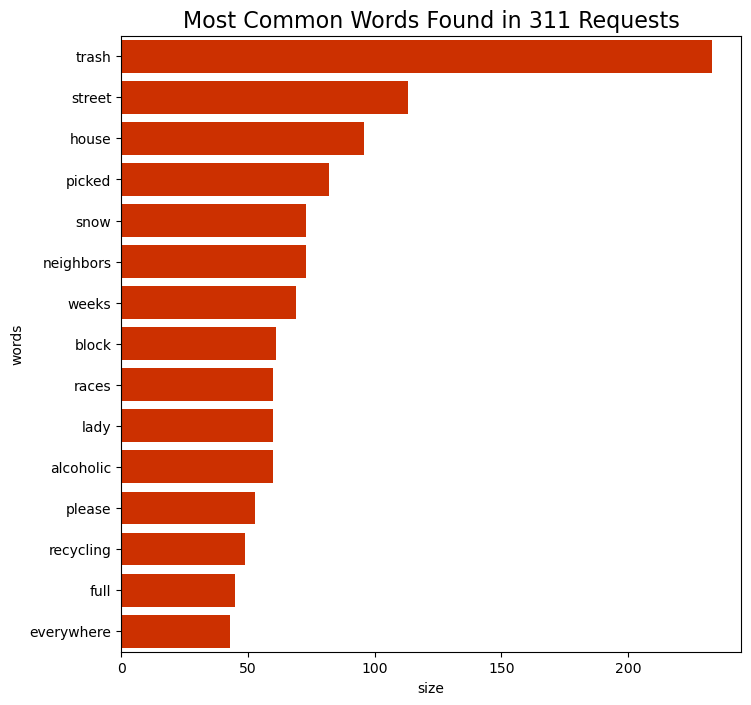

In [132]:
fig, ax = plt.subplots(figsize=(8, 8))

# Plot horizontal bar graph
sns.barplot(
    y="words",
    x="size",
    data=top15,
    ax=ax,
    color="#cc3000",
    saturation=1.0,
)

ax.set_title("Most Common Words Found in 311 Requests", fontsize=16);

## Wrap-up and next steps

You can now request API data, parse JSON, build GeoDataFrames, collect paginated records, and summarize text.

**Next lecture:** Query Census data and combine demographic records with geographic boundaries.

**Takeaway:** Philly cares about trash! They don't call it Filthadelphia for nothing...

### Please note that LLMs make the text mining much easier. You can check https://developers.openai.com/api/docs for more details. 